# 09. Deep models, each beside its simple twin

**The question.** Do flexible, "deep" models catch more faults than straight-line ones, and does that happen where the curved share (notebooks 02 to 08) said the links bend? This notebook runs four well-known kinds of deep model on all six datasets. Each is paired with a simple twin that differs from it in one way only: the deep model can bend.

| Deep model | What it does | Its twin | The one difference |
| --- | --- | --- | --- |
| **Autoencoder** | squeezes one reading of all sensors through a narrow middle and rebuilds it (sensors → 64 → b → 64 → sensors) | **PCA**, which keeps b directions | b is set to the number PCA keeps on that dataset; the autoencoder can bend, PCA cannot |
| **LSTM forecaster** | reads the last W readings of all sensors and predicts the next reading of each | **Straight forecaster**: a straight line from the same last W readings to the same next reading | straight line against a network with memory |
| **GDN** (graph deviation network; Deng and Hooi, AAAI 2021) | learns which sensors are related, then forecasts each sensor from the recent readings of its closest relatives | **Straight-link residual**: each sensor from the others, by a straight line | a learned, bending forecast against a straight one |
| **USAD** (Audibert et al., KDD 2020) | rebuilds windows of W readings with one encoder and two decoders trained against each other | **Autoencoder** | windows and the adversarial training |

**Words used here.** A *window* is the last W readings. *Held-aside data* is normal data kept out of training, used to stop training and to choose settings. *Seed* is the starting point of the random numbers; a deep model trained twice with different seeds gives different answers, so each is trained three times.

**Round 3 update, first (section 12, added after everything below).** Three simple, schedule-aware checks were added as rivals. **One of them, the unseen value check, catches as much on the penicillin batches as the autoencoder (0.645 against 0.639: a tie), so the win described next is gone.** By the rule fixed before computing, the autoencoder's edge there was knowing the schedule, not depth. **No deep model now beats the best simple detector on any dataset.**

*As written before round 3:* **The result, first** (written after all runs were finished). **One deep model wins somewhere: on the IndPenSim penicillin batches, the autoencoder catches 0.64 of faulty readings against 0.45 for the best simple detector** (the curved-link residual): +19 points, range +6 to +36, ahead by the 12-point margin. It is also ahead of PCA scored exactly like it (+35 points), so the bend, not the scoring, does the work. Its false alarms carry over like everyone else's. Its gain comes from two kinds of fault that every simple detector misses, and it rests on only 3 of the 10 faulty batches. IndPenSim is also the dataset with the largest curved share (notebook 08).

Nowhere else does a deep model beat the best simple detector. GDN and USAD were dropped before any real data, by a self-check set in advance (section 2). The details, dataset by dataset, follow; section 9 puts them side by side.

*Follow-up round (section 11, added afterwards):* the win holds against PCA scored alike, against the kinked-link detector and with a line set on the recipe batches alone, but it is narrow. It comes from one fault type (the substrate feed fault) in three batches, and it becomes a tie without batch 97 or with seed 1 alone. GDN and USAD still fail the self-check when built and trained as the authors' code does. On faults where one sensor moves on its own, no deep model beats the per-sensor checks.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd
import torch

from adlab import deep, explore, plots, run

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none, on the CPU")
reports = {}

PyTorch 2.14.1+cu130 | GPU: NVIDIA T550 Laptop GPU


## 1. The design

*Written on 16 November before any deep model was run on real data.*

**The same rules as every other detector.** Each dataset keeps the fitting data and the alarm-line rule of its own notebook: the matched-window line for the Tennessee Eastman plants, each run's own line for the water pump (SKAB) and the flow rig (Cranfield), a line per experiment for the metal etcher, one line for IndPenSim. The catch rate is at 1 false alarm in 100, with ranges from resampling the faulty runs or batches. A win needs a gap of at least 12 points with its range clear of zero. No run or batch is scored by a model fitted on it or a copy of it. Faulty data is never used to choose anything.

**Training, the same everywhere.**
- Inputs are standardised with the fit data only.
- About 20% of the fit data is held aside *whole*: every fifth run or batch when the fit data has five or more (metal etch, the two Tennessee Eastman sets, IndPenSim); otherwise the last fifth of each run (SKAB, whose detectors are fitted on the start of each run, and Cranfield, fitted on two long runs).
- Adam, learning rate 0.001, batches of 256 readings, at most 100 passes through the data, stopping when the held-aside error has not improved for 10 passes; the best pass is kept.
- **Settings.** The window W has two options per dataset: Tennessee Eastman 10 or 20 readings, SKAB 10 or 30, Cranfield 10 or 30, metal etch 5 or 10, IndPenSim 5 or 10. Each model has two size options: the LSTM 1 layer of 32 or 2 layers of 64; GDN an embedding of 32 or 64; USAD a middle of 32 or 64. That makes four combinations, and the one with the lowest held-aside error (seed 0) is used. The autoencoder's shape is fixed by its twin and it takes one reading, so it has one setting. The straight forecaster chooses its W the same way.
- **Three seeds** per model. The catch rate reported is the mean over the three seeds, with the spread across seeds; the margin is judged on the mean.
- Every model has fewer than 1 million weights.

**Scores.** Every score at a moment uses only readings up to that moment.
- Autoencoder, LSTM and GDN: each sensor's error is put on the scale of its errors on held-aside normal data, then combined exactly as the straight-link detector does. So the model is the only difference from its twin.
- GDN is also scored with **its paper's own score**: each sensor's error less its median, over its interquartile range (both from held-aside data), a running average over 3 readings, then the largest over sensors.
- USAD keeps its own score: half the first decoder's error plus half the error of the second decoder fed the first one's output, over the window ending now. As in the paper, USAD works on readings scaled to 0–1 using the fit data, and its decoders end in a sigmoid. Its held-aside error, used for stopping and choosing settings, is the first decoder's: the second decoder is trained to rebuild the first one's output badly, on purpose.

**One choice made in the twins.** The LSTM's twin uses exactly the LSTM's inputs (the last W readings of all sensors, the sensor's own included) to predict the same next reading. That is a straight-line forecaster, not the straight-link detector, whose inputs are the other sensors at the same moment. It was chosen so that the network is the only difference.

**Order.** The metal etcher first, as the pilot; then the water pump (SKAB), the Tennessee Eastman plant at one setting (Rieth runs, fitted on the same 20 runs as before), the Cranfield rig, the six-mode plant and IndPenSim.

## 2. Self-checks on simulated data

*Fixed before any deep model was run on real data. A model that fails is dropped (only that model), and the reason is recorded.*

- **Curvature.** On made-up data whose links are curved (the simulator's dial at 1), the autoencoder should rebuild unseen normal readings better than PCA with the same number of directions: its error below 0.8 × PCA's. With straight links (dial at 0) it should not beat PCA by much: its error above 0.8 × PCA's.
- **A broken link.** In made-up data, one sensor's readings are shifted in time half-way through, so it keeps its level and spread but no longer moves with the others. Every model should flag at least 10% of the readings after the break at 1 false alarm in 100: ten times the false-alarm rate. The simple detectors are shown beside them for comparison.
- **On each real dataset** (in each dataset's section): each model's error on its held-aside normal data should beat simply predicting each sensor's average. If it does not, that is reported; nothing is tuned on faults.

The made-up data has 12,000 readings of 8 sensors (10,000 for fitting, in 10 runs). It is larger than the smallest real fit sets, because USAD's training, as the paper describes it, needs many batches per pass.

In [2]:
checks = deep.self_checks()      # about 15 minutes the first time
display(checks["curvature"])
display(checks["link break"])
print("Dropped:", checks["dropped"] or "none")

,components,autoencoder error,PCA error,autoencoder / PCA,expected,passed
simulated links,,,,,,
curve 0,2,0.062,0.061,1.006,above 0.8,True
curve 1,5,0.031,0.039,0.786,below 0.8,True


,caught,passed
detector,,
Autoencoder,0.518,True
LSTM forecaster,0.124,True
GDN,0.024,False
GDN (paper's score),0.029,False
USAD,0.026,False
Straight forecaster,0.097,False
PCA (T2 + SPE),0.043,False
Straight-link residual,0.449,True


Dropped: {'deep_gdn': 'link-break check: caught 0.02, below 0.10', 'deep_gdn_paper': 'link-break check: caught 0.03, below 0.10', 'deep_usad': 'link-break check: caught 0.03, below 0.10'}


**What this shows.**

- **Curvature check: passed.** With straight links, the autoencoder rebuilds unseen readings no better than PCA (its error is 1.01 times PCA's). With curved links it does better (0.79 times PCA's, just under the 0.8 set in advance).
- **Broken-link check:** the autoencoder catches 0.52 and the LSTM 0.12 of the readings after the break: both pass. **GDN (0.02, and 0.03 with its paper's score) and USAD (0.03) fail**, catching hardly more than the 1 in 100 false alarms. **By the rule fixed in advance, GDN (both scores) and USAD are dropped** from the real-data runs. The check is not an easy one. Among the simple detectors shown for comparison, the straight-link detector catches 0.45, but the straight forecaster (0.10) and PCA (0.04) would fail it too. Simple detectors are not dropped by it; the check was set for the deep models only.
- **Why they fail, as far as I can tell.** The broken sensor keeps its own rhythm; only its link to the others breaks. GDN forecasts each sensor mostly from its own recent readings and its few chosen neighbours. On this data its forecasts are poor even before the break (its best held-aside error 0.49, against 0.33 for the LSTM, on the same made-up data), so a broken link hides in its normal errors. USAD scores a whole window of all sensors at once, so one broken sensor out of eight is diluted.

**A note added after the first results (etch, SKAB, Rieth).** The autoencoder beat its twin PCA by 13 points on three datasets in a row. But the two are scored differently: the autoencoder like the straight-link detector, PCA by T² and SPE. So a **PCA twin scored exactly like the autoencoder** was added: the same training part, the same number of directions, the same per-sensor scoring. The column "gap to PCA scored alike" is the bend alone. It was added after seeing results and is marked so. Nothing else was changed.

## 3. Metal etch (the pilot)

Fitted on the 66 fit wafers; scored on the 21 faulty wafers; alarm line per experiment (notebook 07). Training took a few minutes in all.

In [3]:
deep.score("etch")             # trains and scores the first time (see the estimate above); then read from results/cache
reports["etch"] = deep.report("etch")
display(run.rates(reports["etch"]).to_frame("caught at 1 false alarm in 100 (range)"))
deep.table(reports["etch"])

,caught at 1 false alarm in 100 (range)
detector,
"Straight-link residual, stage told",0.43 (0.28-0.58)
Curved-link residual,0.40 (0.27-0.56)
"PCA, scored like the autoencoder",0.40 (0.26-0.55)
CUSUM chart,0.37 (0.27-0.51)
Straight-link residual,0.36 (0.23-0.51)
Kinked-link residual,0.34 (0.23-0.52)
Autoencoder,0.34 (0.19-0.49)
EWMA chart,0.32 (0.20-0.47)
Matrix Profile,0.27 (0.15-0.43)


,caught (mean of 3 seeds),range (seed 0),spread across seeds,twin,twin caught,gap to twin,"gap to twin, range",against twin,gap to PCA scored alike (added),against PCA scored alike,best simple detector,best simple caught,gap to best simple,"gap to best simple, range",against best simple
deep model,,,,,,,,,,,,,,,
Autoencoder,0.34,0.19-0.49,0.031,PCA (T2 + SPE),0.207,0.133,+0.06 to +0.26,ahead,-0.062,tie,"Straight-link residual, stage told",0.427,-0.087,-0.16 to +0.02,tie
LSTM forecaster,0.249,0.10-0.36,0.027,Straight forecaster,0.17,0.079,+0.03 to +0.15,tie,NaN,NaN,"Straight-link residual, stage told",0.427,-0.178,-0.28 to -0.08,behind


In [4]:
deep.training_table("etch")

fits  seconds  passes  \
model       setting                                                       
autoencoder {'b': 14}                                3    32.37     100   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     3    20.21  61.333   
            {'W': 10, 'hidden': 64, 'layers': 2}     1     4.84      34   
            {'W': 5, 'hidden': 32, 'layers': 1}      1     9.86      74   
            {'W': 5, 'hidden': 64, 'layers': 2}      1     6.25      45   

                                                  peak_MB  weights  \
model       setting                                                  
autoencoder {'b': 14}                                18.7     4385   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     64.4     7411   
            {'W': 10, 'hidden': 64, 'layers': 2}    113.1    56275   
            {'W': 5, 'hidden': 32, 'layers': 1}      47.1     7411   
            {'W': 5, 'hidden': 64, 'layers': 2}      80.1    56275   

                                                  held_aside  average  \
model       setting                                                     
autoencoder {'b': 14}                                  0.027    1.009   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}       0.559    1.009   
            {'W': 10, 'hidden': 64, 'layers': 2}       0.558    1.009   
            {'W': 5, 'hidden': 32, 'layers': 1}        0.586    1.009   
            {'W': 5, 'hidden': 64, 'layers': 2}        0.582    1.009   

                                                  beats the average  
model       setting                                                  
autoencoder {'b': 14}                                          True  
lstm        {'W': 10, 'hidden': 32, 'layers': 1}               True  
            {'W': 10, 'hidden': 64, 'layers': 2}               True  
            {'W': 5, 'hidden': 32, 'layers': 1}                True  
            {'W': 5, 'hidden': 64, 'layers': 2}                True

**What this shows.** **Pilot status: the deep models train and score as designed.** Each beats predicting the average on held-aside data (autoencoder 0.03, LSTM 0.56, against about 1.0).

- **Autoencoder 0.34** (3 seeds spread 0.03): ahead of PCA (T² + SPE) by 13 points (+6 to +26). But against PCA scored alike it is 6 points *behind* (a tie), so the gain over PCA is the scoring, not the bend.
- **LSTM forecaster 0.25**: 8 points above its straight twin (0.17), a tie.
- **Against the best simple detector** (the step-told straight-link, 0.43): the autoencoder ties (−9), the LSTM is behind (−18).

## 4. Water pump (SKAB)

Each of the 34 sessions has its own detectors, fitted on its first 400 readings (104 for one session), with each session's own alarm line. So every model is trained 34 times per seed. The held-aside data is the last fifth of each session's fit stretch. One session's stretch is too short for the 30-reading window, so it uses the 10-reading one.

In [5]:
deep.score("skab")             # trains and scores the first time (see the estimate above); then read from results/cache
reports["skab"] = deep.report("skab")
display(run.rates(reports["skab"]).to_frame("caught at 1 false alarm in 100 (range)"))
deep.table(reports["skab"])

,caught at 1 false alarm in 100 (range)
detector,
Straight-link residual,0.64 (0.55-0.73)
Straight forecaster,0.61 (0.51-0.70)
Curved-link residual,0.61 (0.51-0.70)
Kinked-link residual,0.60 (0.49-0.69)
Matrix Profile,0.56 (0.44-0.67)
Autoencoder,0.55 (0.46-0.67)
LSTM forecaster,0.51 (0.40-0.62)
Rolling z-score,0.50 (0.38-0.60)
EWMA chart,0.50 (0.38-0.60)


,caught (mean of 3 seeds),range (seed 0),spread across seeds,twin,twin caught,gap to twin,"gap to twin, range",against twin,gap to PCA scored alike (added),against PCA scored alike,best simple detector,best simple caught,gap to best simple,"gap to best simple, range",against best simple
deep model,,,,,,,,,,,,,,,
Autoencoder,0.546,0.46-0.67,0.014,PCA (T2 + SPE),0.412,0.134,+0.07 to +0.21,ahead,0.271,ahead,Straight-link residual,0.644,-0.098,-0.16 to -0.04,tie
LSTM forecaster,0.514,0.40-0.62,0.002,Straight forecaster,0.611,-0.097,-0.18 to -0.02,tie,NaN,NaN,Straight-link residual,0.644,-0.13,-0.21 to -0.06,behind


In [6]:
deep.training_table("skab")

fits  seconds  passes  \
model       setting                                                       
autoencoder {'b': 5}                                 3     3.25      94   
            {'b': 6}                                27    24.16  83.778   
            {'b': 7}                                72    74.41  87.347   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}    70   116.55  77.571   
            {'W': 10, 'hidden': 64, 'layers': 2}    52    47.98  38.365   
            {'W': 30, 'hidden': 32, 'layers': 1}    41    69.59  76.756   
            {'W': 30, 'hidden': 64, 'layers': 2}    39    33.83  34.667   

                                                  peak_MB  weights  \
model       setting                                                  
autoencoder {'b': 5}                                 17.5     1805   
            {'b': 6}                                   18     1934   
            {'b': 7}                                 18.1     2063   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     41.9     5640   
            {'W': 10, 'hidden': 64, 'layers': 2}     65.7    52744   
            {'W': 30, 'hidden': 32, 'layers': 1}       61     5640   
            {'W': 30, 'hidden': 64, 'layers': 2}    111.3    52744   

                                                  held_aside  average  \
model       setting                                                     
autoencoder {'b': 5}                                   0.101    1.103   
            {'b': 6}                                   0.256    1.342   
            {'b': 7}                                   0.187    1.232   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}       0.892    1.238   
            {'W': 10, 'hidden': 64, 'layers': 2}        0.97    1.299   
            {'W': 30, 'hidden': 32, 'layers': 1}       0.892    1.233   
            {'W': 30, 'hidden': 64, 'layers': 2}       0.982    1.256   

                                                  beats the average  
model       setting                                                  
autoencoder {'b': 5}                                           True  
            {'b': 6}                                           True  
            {'b': 7}                                           True  
lstm        {'W': 10, 'hidden': 32, 'layers': 1}               True  
            {'W': 10, 'hidden': 64, 'layers': 2}               True  
            {'W': 30, 'hidden': 32, 'layers': 1}               True  
            {'W': 30, 'hidden': 64, 'layers': 2}               True

**What this shows.**

- **Autoencoder 0.55:** ahead of PCA (T² + SPE) by 13 points (+7 to +21), **and ahead of PCA scored alike by 27 points**: here the bend itself helps, against a straight reconstruction with the same scoring.
- **LSTM forecaster 0.51:** 10 points below its straight twin (0.61), a tie.
- **Against the best simple detector** (the straight-link residual, 0.64): the autoencoder ties (−10), the LSTM is behind (−13).
- Every model beats predicting the average on its held-aside data, in every session.

## 5. Chemical plant, one setting (Rieth runs)

Fitted on the same 20 fault-free runs as notebook 03 (every fifth run held aside), scored on 1,000 faulty runs, with the matched-window alarm line from 50 other fault-free runs.

In [7]:
deep.score("tep_rieth")             # trains and scores the first time (see the estimate above); then read from results/cache
reports["tep_rieth"] = deep.report("tep_rieth")
display(run.rates(reports["tep_rieth"]).to_frame("caught at 1 false alarm in 100 (range)"))
deep.table(reports["tep_rieth"])

,caught at 1 false alarm in 100 (range)
detector,
Kinked-link residual,0.83 (0.81-0.85)
Curved-link residual,0.83 (0.81-0.85)
Straight-link residual,0.83 (0.81-0.85)
Straight forecaster,0.83 (0.81-0.84)
LSTM forecaster,0.80 (0.78-0.82)
"PCA, scored like the autoencoder",0.79 (0.77-0.81)
Autoencoder,0.78 (0.76-0.80)
Matrix Profile,0.74 (0.72-0.76)
CUSUM chart,0.68 (0.65-0.70)


,caught (mean of 3 seeds),range (seed 0),spread across seeds,twin,twin caught,gap to twin,"gap to twin, range",against twin,gap to PCA scored alike (added),against PCA scored alike,best simple detector,best simple caught,gap to best simple,"gap to best simple, range",against best simple
deep model,,,,,,,,,,,,,,,
Autoencoder,0.778,0.76-0.80,0.001,PCA (T2 + SPE),0.645,0.133,+0.12 to +0.15,ahead,-0.012,tie,Kinked-link residual,0.833,-0.055,-0.06 to -0.05,tie
LSTM forecaster,0.804,0.78-0.82,0.001,Straight forecaster,0.827,-0.023,-0.03 to -0.02,tie,NaN,NaN,Kinked-link residual,0.833,-0.028,-0.03 to -0.02,tie


In [8]:
deep.training_table("tep_rieth")

fits  seconds  passes  \
model       setting                                                       
autoencoder {'b': 31}                                3    47.57  87.333   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     3    58.88     100   
            {'W': 10, 'hidden': 64, 'layers': 2}     1    13.65      60   
            {'W': 20, 'hidden': 32, 'layers': 1}     1    17.41     100   
            {'W': 20, 'hidden': 64, 'layers': 2}     1    12.33      57   

                                                  peak_MB  weights  \
model       setting                                                  
autoencoder {'b': 31}                                21.6    10835   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     98.9    12724   
            {'W': 10, 'hidden': 64, 'layers': 2}    173.1    66868   
            {'W': 20, 'hidden': 32, 'layers': 1}    164.8    12724   
            {'W': 20, 'hidden': 64, 'layers': 2}    291.2    66868   

                                                  held_aside  average  \
model       setting                                                     
autoencoder {'b': 31}                                  0.101    1.051   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}       0.465    1.051   
            {'W': 10, 'hidden': 64, 'layers': 2}       0.474    1.051   
            {'W': 20, 'hidden': 32, 'layers': 1}       0.466    1.051   
            {'W': 20, 'hidden': 64, 'layers': 2}       0.475    1.051   

                                                  beats the average  
model       setting                                                  
autoencoder {'b': 31}                                          True  
lstm        {'W': 10, 'hidden': 32, 'layers': 1}               True  
            {'W': 10, 'hidden': 64, 'layers': 2}               True  
            {'W': 20, 'hidden': 32, 'layers': 1}               True  
            {'W': 20, 'hidden': 64, 'layers': 2}               True

**What this shows.**

- **Autoencoder 0.78:** ahead of PCA (T² + SPE) by 13 points (+12 to +15), but level with PCA scored alike (−1): again the scoring, not the bend.
- **LSTM forecaster 0.80:** 2 points below its straight twin (0.83), a tie.
- **The best simple detectors** catch 0.83: the kinked-link, curved-link and straight-link residuals, all within a point. Both deep models are behind them by 3 to 6 points. With 1,000 runs the ranges are narrow (about ±1 point), so these small gaps are real. But they are well under the margin, so they count as ties.

## 6. Flow rig (Cranfield)

Fitted on normal runs T2 and T3 (the last fifth of each held aside), scored on the 16 faulty runs, each run with its own alarm line (as for ranking in notebook 05).

In [9]:
deep.score("cranfield")             # trains and scores the first time (see the estimate above); then read from results/cache
reports["cranfield"] = deep.report("cranfield")
display(run.rates(reports["cranfield"]).to_frame("caught at 1 false alarm in 100 (range)"))
deep.table(reports["cranfield"])

,caught at 1 false alarm in 100 (range)
detector,
Kinked-link residual,0.40 (0.28-0.53)
Straight-link residual,0.38 (0.27-0.51)
Curved-link residual,0.37 (0.26-0.50)
LSTM forecaster,0.28 (0.16-0.39)
PCA (T2 + SPE),0.26 (0.15-0.39)
"PCA, scored like the autoencoder",0.26 (0.14-0.40)
Matrix Profile,0.25 (0.14-0.38)
Autoencoder,0.24 (0.11-0.37)
EWMA chart,0.24 (0.13-0.37)


,caught (mean of 3 seeds),range (seed 0),spread across seeds,twin,twin caught,gap to twin,"gap to twin, range",against twin,gap to PCA scored alike (added),against PCA scored alike,best simple detector,best simple caught,gap to best simple,"gap to best simple, range",against best simple
deep model,,,,,,,,,,,,,,,
Autoencoder,0.244,0.11-0.37,0.016,PCA (T2 + SPE),0.259,-0.015,-0.05 to +0.02,tie,-0.011,tie,Kinked-link residual,0.397,-0.153,-0.22 to -0.10,behind
LSTM forecaster,0.282,0.16-0.39,0.016,Straight forecaster,0.112,0.17,+0.04 to +0.31,ahead,NaN,NaN,Kinked-link residual,0.397,-0.114,-0.20 to -0.04,tie


In [10]:
deep.training_table("cranfield")

fits  seconds  passes  \
model       setting                                                       
autoencoder {'b': 6}                                 3    39.18      28   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     1    61.11      58   
            {'W': 10, 'hidden': 64, 'layers': 2}     1    82.05      67   
            {'W': 30, 'hidden': 32, 'layers': 1}     3   360.59     100   
            {'W': 30, 'hidden': 64, 'layers': 2}     1    93.72      63   

                                                  peak_MB  weights  \
model       setting                                                  
autoencoder {'b': 6}                                 22.5     3869   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}    161.4     8055   
            {'W': 10, 'hidden': 64, 'layers': 2}    306.5    57559   
            {'W': 30, 'hidden': 32, 'layers': 1}    415.4     8055   
            {'W': 30, 'hidden': 64, 'layers': 2}    790.5    57559   

                                                  held_aside  average  \
model       setting                                                     
autoencoder {'b': 6}                                   0.173    0.891   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}       0.061    0.891   
            {'W': 10, 'hidden': 64, 'layers': 2}       0.065    0.891   
            {'W': 30, 'hidden': 32, 'layers': 1}       0.058    0.891   
            {'W': 30, 'hidden': 64, 'layers': 2}       0.068    0.891   

                                                  beats the average  
model       setting                                                  
autoencoder {'b': 6}                                           True  
lstm        {'W': 10, 'hidden': 32, 'layers': 1}               True  
            {'W': 10, 'hidden': 64, 'layers': 2}               True  
            {'W': 30, 'hidden': 32, 'layers': 1}               True  
            {'W': 30, 'hidden': 64, 'layers': 2}               True

**What this shows.**

- **Autoencoder 0.24:** level with PCA (0.26) and with PCA scored alike.
- **LSTM forecaster 0.28: ahead of its straight twin by 17 points (+4 to +31): a win by the margin.** But its twin is weak here: the straight forecaster catches only 0.11, far below the straight-link detector (0.38). Forecasting the next second from the last 10 or 30 seconds is a poor detector on this rig, whichever model does it.
- **Against the best simple detector** (the kinked-link residual, 0.40): the LSTM ties (−11), the autoencoder is behind (−15).

## 7. Chemical plant, six modes

Fitted on the 24 fit runs of notebook 06 (every fifth run held aside), scored on the 168 faulty runs, with the one matched-window alarm line from 6 other normal runs.

In [11]:
deep.score("tep6")             # trains and scores the first time (see the estimate above); then read from results/cache
reports["tep6"] = deep.report("tep6")
display(run.rates(reports["tep6"]).to_frame("caught at 1 false alarm in 100 (range)"))
deep.table(reports["tep6"])

,caught at 1 false alarm in 100 (range)
detector,
Straight forecaster,0.69 (0.63-0.75)
"Straight-link residual, stage told, balanced folds",0.68 (0.63-0.76)
"Straight-link residual, balanced folds",0.67 (0.61-0.75)
LSTM forecaster,0.59 (0.53-0.67)
Kinked-link residual,0.51 (0.46-0.56)
"PCA, scored like the autoencoder",0.47 (0.40-0.55)
Curved-link residual,0.46 (0.41-0.52)
Straight-link residual,0.46 (0.41-0.51)
Autoencoder,0.44 (0.36-0.55)


,caught (mean of 3 seeds),range (seed 0),spread across seeds,twin,twin caught,gap to twin,"gap to twin, range",against twin,gap to PCA scored alike (added),against PCA scored alike,best simple detector,best simple caught,gap to best simple,"gap to best simple, range",against best simple
deep model,,,,,,,,,,,,,,,
Autoencoder,0.436,0.36-0.55,0.009,PCA (T2 + SPE),0.234,0.202,+0.15 to +0.30,ahead,-0.038,tie,Straight forecaster,0.686,-0.249,-0.31 to -0.17,behind
LSTM forecaster,0.593,0.53-0.67,0.007,Straight forecaster,0.686,-0.092,-0.12 to -0.07,tie,NaN,NaN,Straight forecaster,0.686,-0.092,-0.12 to -0.07,tie


In [12]:
deep.training_table("tep6")

fits  seconds  passes  \
model       setting                                                       
autoencoder {'b': 4}                                 3   188.53      93   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     1   115.43     100   
            {'W': 10, 'hidden': 64, 'layers': 2}     1   208.56      78   
            {'W': 20, 'hidden': 32, 'layers': 1}     1    48.56     100   
            {'W': 20, 'hidden': 64, 'layers': 2}     3   193.35      87   

                                                  peak_MB  weights  \
model       setting                                                  
autoencoder {'b': 4}                                 31.6     7352   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}      184    12724   
            {'W': 10, 'hidden': 64, 'layers': 2}    329.2    66868   
            {'W': 20, 'hidden': 32, 'layers': 1}    325.4    12724   
            {'W': 20, 'hidden': 64, 'layers': 2}    585.4    66868   

                                                  held_aside  average  \
model       setting                                                     
autoencoder {'b': 4}                                   0.026    1.137   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}       0.078    1.137   
            {'W': 10, 'hidden': 64, 'layers': 2}       0.078    1.137   
            {'W': 20, 'hidden': 32, 'layers': 1}       0.077    1.137   
            {'W': 20, 'hidden': 64, 'layers': 2}       0.077    1.137   

                                                  beats the average  
model       setting                                                  
autoencoder {'b': 4}                                           True  
lstm        {'W': 10, 'hidden': 32, 'layers': 1}               True  
            {'W': 10, 'hidden': 64, 'layers': 2}               True  
            {'W': 20, 'hidden': 32, 'layers': 1}               True  
            {'W': 20, 'hidden': 64, 'layers': 2}               True

**What this shows.**

- **The straight forecaster is the best detector on this plant: 0.69** (0.63 to 0.75), 23 points above the straight-link detector (0.46), which led in notebook 06. A straight line from the last 10 or 20 readings of every sensor to the next one catches far more of these faults than a straight line from the other sensors at the same moment. On this plant, a sensor's recent past says much more than the other sensors do now.
- **LSTM forecaster 0.59:** 9 points *below* its straight twin, a tie by the margin, and the same against the best simple detector (which here is that same straight forecaster).
- **Autoencoder 0.44:** ahead of PCA (T² + SPE) by 20 points, but 4 points behind PCA scored alike (a tie). Again the gain is the scoring, not the bend.
- The kinked-link detector (0.51) edges past the straight-link and curved-link ones (0.46). The gap is under the margin.

## 8. Penicillin batches (IndPenSim)

Fitted on the 60 fit batches of notebook 08 (every fifth one held aside), scored on the 10 faulty batches, with one alarm line from the 30 line batches. Only 10 faulty batches: ranges are wide.

In [13]:
deep.score("indpensim")             # trains and scores the first time (see the estimate above); then read from results/cache
reports["indpensim"] = deep.report("indpensim")
display(run.rates(reports["indpensim"]).to_frame("caught at 1 false alarm in 100 (range)"))
deep.table(reports["indpensim"])

,caught at 1 false alarm in 100 (range)
detector,
Unseen value check,0.64 (0.37-0.87)
Autoencoder,0.64 (0.55-0.87)
Nearest normal reading (k = 1),0.59 (0.29-0.82)
Curved-link residual,0.45 (0.25-0.71)
Straight-link residual,0.44 (0.25-0.70)
"Straight-link residual, stage told",0.44 (0.25-0.70)
LSTM forecaster,0.44 (0.25-0.75)
Nearest normal readings (k = 5),0.40 (0.25-0.65)
Kinked-link residual,0.40 (0.22-0.65)


,caught (mean of 3 seeds),range (seed 0),spread across seeds,twin,twin caught,gap to twin,"gap to twin, range",against twin,gap to PCA scored alike (added),against PCA scored alike,best simple detector,best simple caught,gap to best simple,"gap to best simple, range",against best simple
deep model,,,,,,,,,,,,,,,
Autoencoder,0.639,0.55-0.87,0.049,PCA (T2 + SPE),0.343,0.296,+0.15 to +0.45,ahead,0.354,ahead,Unseen value check,0.645,-0.006,-0.33 to +0.42,tie
LSTM forecaster,0.441,0.25-0.75,0.041,Straight forecaster,0.121,0.32,+0.12 to +0.58,ahead,NaN,NaN,Unseen value check,0.645,-0.204,-0.62 to +0.34,tie


In [14]:
deep.training_table("indpensim")

fits  seconds  passes  \
model       setting                                                       
autoencoder {'b': 9}                                 9  1455.62  86.333   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}     1    36.91      54   
            {'W': 10, 'hidden': 64, 'layers': 2}     1    34.13      41   
            {'W': 5, 'hidden': 32, 'layers': 1}      1    46.11      65   
            {'W': 5, 'hidden': 64, 'layers': 2}      9  1786.16  61.222   

                                                  peak_MB  weights  \
model       setting                                                  
autoencoder {'b': 9}                                 35.4     3869   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}    164.9     7572   
            {'W': 10, 'hidden': 64, 'layers': 2}    309.1    56596   
            {'W': 5, 'hidden': 32, 'layers': 1}     101.9     7572   
            {'W': 5, 'hidden': 64, 'layers': 2}     192.5    56596   

                                                  held_aside  average  \
model       setting                                                     
autoencoder {'b': 9}                                   0.011     1.06   
lstm        {'W': 10, 'hidden': 32, 'layers': 1}        0.11    1.189   
            {'W': 10, 'hidden': 64, 'layers': 2}       0.087    1.189   
            {'W': 5, 'hidden': 32, 'layers': 1}        0.106    1.189   
            {'W': 5, 'hidden': 64, 'layers': 2}        0.043     1.06   

                                                  beats the average  
model       setting                                                  
autoencoder {'b': 9}                                           True  
lstm        {'W': 10, 'hidden': 32, 'layers': 1}               True  
            {'W': 10, 'hidden': 64, 'layers': 2}               True  
            {'W': 5, 'hidden': 32, 'layers': 1}                True  
            {'W': 5, 'hidden': 64, 'layers': 2}                True

**What this shows.**

- **Autoencoder 0.64** (range 0.55 to 0.87; spread across seeds 0.05). It is **ahead of the best simple detector of the time** (the curved-link residual, 0.45) by **+19 points (+6 to +36)** (*round 3: counting the schedule-aware checks of section 12, the best simple detector is the unseen value check, 0.645, and the gap is −0.6, a tie; the table above already shows it*), ahead of PCA (T² + SPE) by 30 points and ahead of PCA scored alike by 35. **This is the one deep-model win in the notebook.**
- **Where it comes from.** On the faults the simple detectors already catch (timings B, C and D in notebook 08) the autoencoder is level with them or a little better. Its gain is on **timings A and E**, which the best simple detector misses: it catches 0.44 and 0.43 of those readings, where the best simple detector catches 0.02 and 0.00. (*Corrected in the follow-up round:* this first said "every simple detector"; the CUSUM chart catches part of them, with a line that does not carry over. See section 11b.) These are only 3 batches (91, 97 and 95).
- **Its line carries over.** Before the faults it gives 0.001 false alarms, and between a fault's stretches 0.048, the same as the straight-link detector (0.047). So the 0.64 is a fair catch rate at the same false-alarm rate as the others.
- **LSTM forecaster 0.44:** far above its straight twin (0.12, a weak detector here, as on Cranfield), and level with the best simple detector.
- Both models beat predicting the average on held-aside data by a wide margin (0.03 and 0.09, against 1.19).

## 9. All six datasets side by side

For each dataset and deep model: its catch rate (mean of three seeds), its gap to its twin, its gap to PCA scored alike (autoencoder only, added after the first results), and its gap to the best simple detector on that dataset. A win needs 12 points with a range clear of zero.

**What "best simple" means.** The best of every detector that is not deep: the eight standard ones, the step- or mode-told straight-link, the kinked-link, the straight forecaster and, since the follow-up round, PCA scored like the autoencoder (*added after seeing results*). Adding the PCA twin moved no number: it is never the best on any dataset. On the penicillin batches, the best simple detector's 0.45 (the curved-link residual) already counted the straight forecaster (0.12); PCA scored alike (0.29) is below it too. The chart shows each model's gap to its twin.

In [15]:
overview = deep.overview(reports)
overview

caught (mean of 3 seeds)  \
dataset                                  deep model                                 
Metal etch                               Autoencoder                         0.34   
                                         LSTM forecaster                    0.249   
Water pump (SKAB)                        Autoencoder                        0.546   
                                         LSTM forecaster                    0.514   
Chemical plant, one setting (Rieth runs) Autoencoder                        0.778   
                                         LSTM forecaster                    0.804   
Flow rig (Cranfield)                     Autoencoder                        0.244   
                                         LSTM forecaster                    0.282   
Chemical plant, six modes                Autoencoder                        0.436   
                                         LSTM forecaster                    0.593   
Penicillin batches (IndPenSim)           Autoencoder                        0.639   
                                         LSTM forecaster                    0.441   

                                                         range (seed 0)  \
dataset                                  deep model                       
Metal etch                               Autoencoder          0.19-0.49   
                                         LSTM forecaster      0.10-0.36   
Water pump (SKAB)                        Autoencoder          0.46-0.67   
                                         LSTM forecaster      0.40-0.62   
Chemical plant, one setting (Rieth runs) Autoencoder          0.76-0.80   
                                         LSTM forecaster      0.78-0.82   
Flow rig (Cranfield)                     Autoencoder          0.11-0.37   
                                         LSTM forecaster      0.16-0.39   
Chemical plant, six modes                Autoencoder          0.36-0.55   
                                         LSTM forecaster      0.53-0.67   
Penicillin batches (IndPenSim)           Autoencoder          0.55-0.87   
                                         LSTM forecaster      0.25-0.75   

                                                         spread across seeds  \
dataset                                  deep model                            
Metal etch                               Autoencoder                   0.031   
                                         LSTM forecaster               0.027   
Water pump (SKAB)                        Autoencoder                   0.014   
                                         LSTM forecaster               0.002   
Chemical plant, one setting (Rieth runs) Autoencoder                   0.001   
                                         LSTM forecaster               0.001   
Flow rig (Cranfield)                     Autoencoder                   0.016   
                                         LSTM forecaster               0.016   
Chemical plant, six modes                Autoencoder                   0.009   
                                         LSTM forecaster               0.007   
Penicillin batches (IndPenSim)           Autoencoder                   0.049   
                                         LSTM forecaster               0.041   

                                                                         twin  \
dataset                                  deep model                             
Metal etch                               Autoencoder           PCA (T2 + SPE)   
                                         LSTM forecaster  Straight forecaster   
Water pump (SKAB)                        Autoencoder           PCA (T2 + SPE)   
                                         LSTM forecaster  Straight forecaster   
Chemical plant, one setting (Rieth runs) Autoencoder           PCA (T2 + SPE)   
                                         LSTM forecaster  Straight forecaster   
Flow rig (Cranfield)                     Autoe

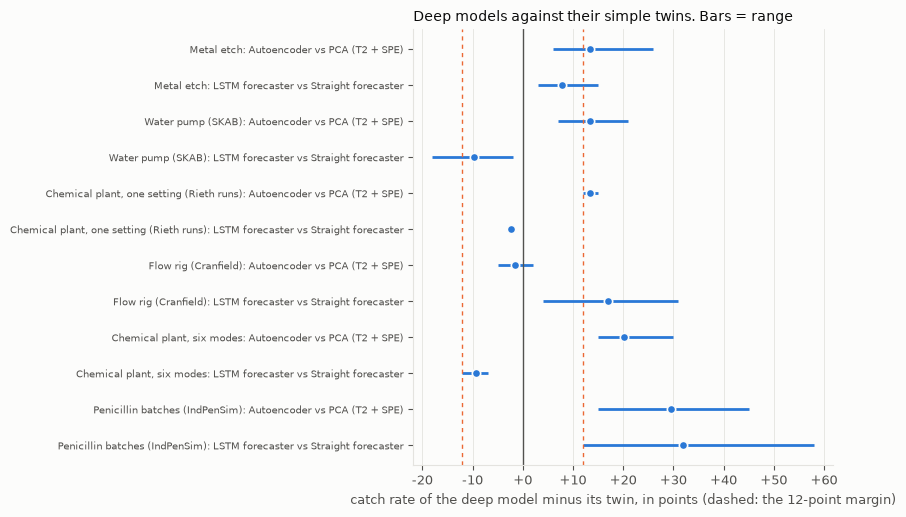

In [16]:
deep.overview_plot(overview);

**What this shows.**

| Dataset | Autoencoder vs PCA | vs PCA scored alike | vs best simple | LSTM vs its twin | vs best simple |
| --- | --- | --- | --- | --- | --- |
| Metal etch | +13, ahead | −6, tie | −9, tie | +8, tie | −18, behind |
| Water pump | +13, ahead | **+27, ahead** | −10, tie | −10, tie | −13, behind |
| Plant, one setting | +13, ahead | −1, tie | −5, tie | −2, tie | −3, tie |
| Flow rig | −1, tie | −1, tie | −15, behind | **+17, ahead** | −11, tie |
| Plant, six modes | +20, ahead | −4, tie | −25, behind | −9, tie | −9, tie |
| Penicillin batches | +30, ahead | **+35, ahead** | −1, tie (+19, ahead, before round 3) | **+32, ahead** | −20, tie |

(Gaps in points; mean of three seeds.)

- **The autoencoder's 13-point lead over PCA on four datasets is mostly the scoring.** Against PCA scored exactly like it, the lead disappears on four datasets and stays on two: the water pump and the penicillin batches.
- **The LSTM beats its straight twin only where that twin is weak** (the flow rig and the penicillin batches, where the straight forecaster catches 0.11 and 0.12). On the plant in six modes, the straight forecaster is the best detector of all (0.69), and the LSTM does not match it.
- **Against the best simple detector, no deep model wins.** Before round 3 the autoencoder won once, on the penicillin batches; counting the schedule-aware checks (section 12), that became a tie.
- The spread across seeds is small everywhere: 0.001 to 0.05.

## 10. Summary, training cost and what was dropped

**Wins.** None against the best simple detector, once the schedule-aware checks are counted (round 3, section 12). Before them, there was one: the autoencoder on IndPenSim (+19 points, +6 to +36). Against their twins, the autoencoder wins on two datasets once the twin is scored alike (the water pump, IndPenSim), and the LSTM on two (the flow rig, IndPenSim), both where its twin is a weak detector.

**Dropped.** GDN (both scores) and USAD, by the broken-link self-check fixed in advance (section 2): they catch 0.02 to 0.03 of a broken link, under the 0.10 required. They were not run on real data.

**Cost.** All deep training together took about 39 minutes on the NVIDIA T550 laptop GPU: 102 autoencoder and 226 LSTM fits, most of them the water pump's 34 small sessions. The largest network had about 67,000 weights (the limit was 1 million). The most GPU memory used was 790 MB (the LSTM with a 30-reading window on the flow rig).

**Choices, and when they were made.**

- Before any real data: every setting, window option, stopping rule, scoring rule, the twins and the self-checks (sections 1 and 2).
- After the first results: the PCA twin scored like the autoencoder. Nothing was tuned on faults.

## 11. Follow-up round: checks on the results above

*Everything in this section was added after all the results above, on 16-17 November. No setting of any detector was changed, nothing was tuned on faults, and the alarm-line rules are those of each dataset. The checks were fixed before they were computed, as written at the start of each part.*

### 11a. GDN and USAD against the authors' code

*Fixed before computing.* GDN and USAD failed the broken-link check (section 2). A model built to catch broken links failing such a check points first at our implementation. So both were compared with the authors' code (GDN: github.com/d-ailin/GDN; USAD: github.com/manigalati/usad) on input scaling, windows, the graph, training length and the score. Then each difference was tried on the **simulated check only** (never on real faults), three seeds each, moving one step at a time towards the authors' code. Only real bugs would be fixed, and the 0.10 bar stays.

| | GDN, authors' code | GDN, ours | USAD, authors' code | USAD, ours |
| --- | --- | --- | --- | --- |
| Input scaling | 0 to 1 on the fit data | standardised | 0 to 1 on the fit data | 0 to 1 on the fit data |
| Windows | the last 5 readings (their run.sh) predict the next | the last 10 or 20 (chosen on held-aside data) predict the next | windows of 12, flattened | windows of 10 or 20, flattened |
| Graph | each sensor's top 5 by embedding similarity, itself included (itself + 4) | itself + up to 10 others: all 7 others on the 8-sensor check | none | none |
| Network | attention on the transformed window and the embedding, a bias, batch norm, ReLU, times the embedding, batch norm, ReLU, dropout 0.2, one linear layer | the same attention; ReLU then batch norm, times the embedding, two linear layers, no dropout | layers of input/2, input/4, then a latent space of W x 100 | the same, with hidden layers capped at 256 and 128, latent 32 or 64 |
| Training | batch 32, 30 passes, stop after 15 without improvement on a random 20% stretch | batch 256, up to 100 passes, stop after 10, every fifth run held aside | batch 7,919, 100 passes, the last one kept; gradients carried between the two phases | batch 256, up to 100 passes, stop after 10 on the first decoder's error; gradients cleared before each phase |
| Score | each sensor's error less its median, over its interquartile range + 0.01, with median and range **from the scored data itself**; mean of the last 4; largest over sensors | the same, with median and range from held-aside normal data; mean of the last 3; also the straight-link detector's score | 0.5 x first decoder's error + 0.5 x second decoder fed the first one's output | the same |

In [17]:
from adlab import authors_check, followup, indpensim
authors_check.table()          # read from results/cache; about 1.5 hours on the GPU to compute again

seed 0  \
model variant                                                      score                        
GDN   ours (W 10, dim 64)                                          link score           0.068   
                                                                   paper score          0.046   
      authors' network, our graph size, our training               link score           0.053   
                                                                   paper score          0.038   
      authors' network, top-5 graph (self + 4)                     link score           0.042   
                                                                   paper score          0.004   
      authors' network + min-max scaling                           link score           0.042   
                                                                   paper score          0.033   
      authors' network + their run.sh training (W 5, batch 32, ... link score           0.042   
                                                                   paper score          0.032   
      as above + their smoothing (4 readings) and IQR + 0.01       link score           0.042   
                                                                   paper score          0.036   
      as above + median/IQR from the scored data itself (their ... link score           0.042   
                                                                   paper score          0.033   
USAD  ours (W 10, latent 32)                                       USAD score           0.006   
                                                                   first decoder only    0.09   
      their gradient handling                                      USAD score           0.017   
                                                                   first decoder only   0.023   
      their layer sizes (latent W x 100)                           USAD score           0.009   
                                                                   first decoder only   0.009   
      their gradient handling + layer sizes                        USAD score           0.024   
                                                                   first decoder only   0.059   
      their code as released (W 12, latent 1200, batch 7919, 10... USAD score            0.01   
                                                                   first decoder only   0.008   
      their training only (batch 7919, 100 passes, last kept), ... USAD score           0.005   
                                                                   first decoder only   0.004   

                                                                                       seed 1  \
model variant                                                      score                        
GDN   ours (W 10, dim 64)                                          link score           0.052   
                                                                   paper score          0.038   
      authors' network, our graph size, our training               link score           0.053   
                                                                   paper score          0.036   
      authors' network, top-5 graph (self + 4)                     link score           0.055   
                                                                   paper score          0.035   
      authors' network + min-max scaling                           link score           0.053   
                                                                   paper score          0.042   
      authors' network + their run.sh training (W 5, batch 32, ... link score            0.05   
                                                                   paper score          0.029   
      as above + their smoothing (4 readings) and IQR + 0.01       link score            0.05   
                                                                   paper score          0.036   
      as abo

**What this shows. No variant passes.** Across 7 versions of GDN and 6 of USAD, three seeds each, the best single seed catches 0.087 of the broken link (GDN, the authors' network trained as their run.sh trains it), and the best USAD 0.092 (its first decoder alone). None reaches 0.10. Moving GDN step by step to the authors' network, graph, scaling, training and smoothing changes its catch rate by a couple of points at most. USAD exactly as the authors' code runs it catches 0.01.

**No real bug was found.** The differences are choices, not mistakes. Our GDN puts its layers in a slightly different order and has one more hidden layer. Our USAD follows the paper's two losses exactly. The authors' code updates in the order backward, step, clear, so gradients from one phase leak into the next update and weaken the second decoder's adversarial part. Neither difference changes the result here. One thing in the authors' GDN code breaks this project's rules: it scales each sensor's error by the median and range of the very data it is scoring. Shown for completeness in the last GDN row, it does not help either.

**The likely reason both fail.** The check breaks a link by sliding one sensor's second half 137 readings along. The sensor stays smooth and keeps its own rhythm; it only stops matching the others. GDN forecasts each sensor from the last few readings of itself and its neighbours, and a sensor's own past still predicts its next reading well, broken link or not. USAD rebuilds whole windows, and its narrowest layer (20 to 64 numbers for a window of 80 or more) has room to rebuild a smooth window that does not match the others. The straight forecaster (0.10) and the LSTM forecaster (0.12), which also lean on each sensor's own past, sit near the bar too. The autoencoder (0.52) and the straight-link detector (0.45) look at one moment at a time, where the broken link shows.

**So GDN and USAD stay out.** The fairest wording: they failed a basic self-check in our implementation, and moving our implementation to the authors' code did not change that.

### 11b. The one win, under pressure

*Fixed before computing.* The autoencoder's win on the penicillin batches rests on 10 faulty batches. Five checks, none of which changes a setting:

1. **Which batches carry it, and their fault types.** The data does not name the faults, but the simulator's code does: its Python port (PenSimPy) forces one controller output to a fixed value over fixed hours for each of its process faults. A batch's fault type is the catalogue fault whose hours and forced values match its fault flag (`indpensim.fault_types`).
2. **Each faulty batch left out in turn**, with the best simple detector picked again each time.
3. **Each of the autoencoder's three seeds alone**, against the best simple detector.
4. **The alarm line set on the recipe batches alone**, the second line planned in notebook 08 (the faulty batches follow the recipe).
5. **Against PCA scored like the autoencoder and against the kinked-link detector.**

In [18]:
indpensim.fault_types()

,timing,fault stretches (h),batch ends (h),fault type,controller output held at
batch,,,,,
91,A,"20-30, 76-92, 200-214",258,substrate feed,"2, 20"
92,B,"80-84, 140-160",230,base flow,"5, 10"
93,C,70-90,210,coolant flow,2
94,D,"20-24, 100-110",230,aeration,20
95,E,"20-30, 76-92, 200-211",211,substrate feed,"2, 20"
96,C,70-90,230,coolant flow,2
97,A,"20-30, 76-92, 200-214",225,substrate feed,"2, 20"
98,B,"80-84, 140-160",230,base flow,"5, 10"
99,D,"20-24, 100-110",251,aeration,20


**Fault types.** Every faulty batch matches exactly one fault of the simulator's catalogue, and each timing group of notebook 08 is one fault type. A (91, 97) and E (95) are both the **substrate feed fault**: the sugar feed is held at 2 L/h from 20 to 30 hours, then at 20 L/h from 76 to 92 hours and from 200 to 214 hours. Batch 95 is the same fault in a shorter batch, which ends at 211 hours. B (92, 98) is the base flow fault, C (93, 96) the coolant flow fault and D (94, 99, 100) the aeration fault.

In [19]:
followup.ips_by_batch()

,fault type,timing,faulty readings,Autoencoder,Curved-link residual,Straight-link residual,Kinked-link residual,"PCA, scored like the autoencoder",Straight forecaster,LSTM forecaster,Unseen value check,Nearest normal reading (k = 1),best simple detector on this batch (seed 0),which,"autoencoder minus curved-link, points"
batch,,,,,,,,,,,,,,,
91,substrate feed,A,203,0.292,0.02,0.025,0.034,0,0.02,0.033,1,0.892,1,Unseen value check,27.258
92,base flow,B,122,0.828,0.787,0.811,0.59,0,0.008,0.844,0,0,0.943,"Nearest normal reading, all sensors (k = 1)",4.098
93,coolant flow,C,101,0.851,0.842,0.693,0.683,0.723,0.455,0.667,0,0,0.842,Curved-link residual,0.99
94,aeration,D,72,1,1,1,1,1,0.208,0.995,1,1,1,PCA (T2 + SPE),0
95,substrate feed,E,188,0.321,0,0,0.005,0,0.021,0.009,1,0.862,1,Unseen value check,32.092
96,coolant flow,C,101,0.683,0.693,0.644,0.634,0.683,0.287,0.624,0,0,0.693,Curved-link residual,-0.99
97,substrate feed,A,203,0.521,0.01,0.02,0.025,0,0.02,0.01,1,0.872,1,Unseen value check,51.067
98,base flow,B,122,0.866,0.77,0.803,0.533,0,0.008,0.781,0,0,0.951,"Nearest normal reading, all sensors (k = 1)",9.563
99,aeration,D,72,1,1,1,1,1,0.292,0.995,1,1,1,PCA (T2 + SPE),0


*Round 3: the table above now also lists the unseen value check and the nearest-neighbour check (section 12), and its "best simple detector on this batch" counts them: the unseen value check catches every faulty reading of the three substrate feed batches. The reading below is as written before round 3.*

**Which batches carry the win.** All of it comes from the three substrate feed batches. The autoencoder catches 0.29, 0.32 and 0.52 of their faulty readings, where the curved-link detector catches 0.02, 0.00 and 0.01: gains of 27, 32 and 51 points. On the other seven batches the two are level (within 10 points; equal on the aeration batches, where every detector catches everything). Of the simple detectors, only the CUSUM chart catches part of batches 91 and 95 (0.35 and 0.30, about what the autoencoder catches there), but its line does not carry over: on the faulty batches' own normal readings it gives 0.36 false alarms, 36 times the intended rate. **Batch 97 every simple detector misses** (the best catches 0.03); the autoencoder catches 0.52 of it.

*A correction to section 8.* Section 8 says timings A and E are faults "which every simple detector misses". That holds for the best simple detector, but not for every one: the CUSUM chart catches part of them, with the false alarms just described.

In [20]:
display(followup.ips_leave_one_out()[["fault type left out", "autoencoder caught", "best simple", "best simple caught",
                                       "vs best simple", "vs best simple, range", "vs best simple, verdict"]])
display(followup.ips_per_seed())
followup.ips_summary().T

,fault type left out,autoencoder caught,best simple,best simple caught,vs best simple,"vs best simple, range","vs best simple, verdict"
batch left out,,,,,,,
91,substrate feed,0.706,Unseen value check,0.576,12.979,-19.8 to +54.4,tie
92,base flow,0.619,Unseen value check,0.714,-9.524,-40.0 to +33.9,tie
93,coolant flow,0.621,Unseen value check,0.701,-8.052,-39.3 to +37.1,tie
94,aeration,0.617,Unseen value check,0.623,-0.591,-36.1 to +45.6,tie
95,substrate feed,0.695,Unseen value check,0.582,11.298,-25.3 to +58.8,tie
96,coolant flow,0.635,Unseen value check,0.701,-6.58,-39.9 to +38.5,tie
97,substrate feed,0.662,Unseen value check,0.576,8.579,-29.6 to +55.9,tie
98,base flow,0.615,Unseen value check,0.714,-9.935,-39.4 to +32.6,tie
99,aeration,0.617,Unseen value check,0.623,-0.591,-32.9 to +43.7,tie


,autoencoder caught,best simple,best simple caught,"gap, points",range,verdict
autoencoder seed,,,,,,
seed 0,0.691,Unseen value check,0.645,4.618,-27.6 to +47.5,tie
seed 1,0.573,Unseen value check,0.645,-7.166,-40.6 to +35.7,tie
seed 2,0.654,Unseen value check,0.645,0.876,-34.4 to +42.8,tie


,one line for all strategies (the headline),line from the recipe batches alone
autoencoder caught,0.639,0.68
best simple,Unseen value check,Unseen value check
best simple caught,0.645,0.645
vs best simple,-0.557,3.477
"vs best simple, range",-32.8 to +42.4,-28.4 to +42.8
"vs best simple, verdict",tie,tie
vs PCA scored alike,35.43,36.916
"vs PCA scored alike, range",+17.6 to +54.4,+17.8 to +52.2
"vs PCA scored alike, verdict",ahead,ahead
vs kinked-link,24.204,31.502


*Round 3: the three tables above now count the schedule-aware checks of section 12, so their best simple detector is the unseen value check, and every leave-one-out row and every seed is a tie. The reading below is as written before round 3, against the curved-link residual.*

**How robust it is.**

- **Left out one at a time:** the win holds in 9 of the 10 cases (+16 to +21 points, every range clear of zero). Without **batch 97** it becomes **+12.6 (−0.4 to +25.7), a tie**: the range now touches zero. Batch 97 is the substrate feed batch the autoencoder catches best.
- **Seed by seed:** seeds 0 and 2 win (+24.0, range +10.9 to +40.9; +20.2, +5.4 to +37.0). **Seed 1 alone is a tie: +12.2 (−0.2 to +28.0).** The headline uses the mean of the three seeds, as fixed in advance.
- **Line from the recipe batches alone:** the autoencoder catches 0.68 against 0.46: **+21.8 (+6.5 to +37.4), still a win.**
- **Against PCA scored alike, +35 (+18 to +54); against the kinked-link detector, +24 (+12 to +39):** both wins.

**What this says.** The win is real on these data in the sense that matters most here: it is not the scoring (PCA scored alike is far behind) and not a few corners (the kinked-link detector is behind too). But it is narrow. It comes from one fault type in three batches, and it does not survive losing the best of them, or using a less lucky seed. More faulty batches are needed to say more (part C of the follow-up round looks at generating them).

### 11c. One-sensor faults: do deep models beat the per-sensor checks?

*Fixed before computing.* A one-sensor fault is one that the fault-kind table labels "single sensor" on that dataset, under its own alarm line: the per-sensor checks catch at least half of it, and at most three sensors move on their own. On the water pump these are fluid leak or addition, hot water inflow and rotor imbalance (fluid leak sits exactly on the line: the per-sensor checks catch 0.50 of it). On the plant at one setting, faults 4, 5, 7, 10, 11, 17 and 20 (notebook 03, matched line). On the plant in six modes, fault 24 only (notebook 06). The best per-sensor check is the best of rolling z, EWMA and CUSUM on those faults. Each deep model that passed its self-checks is compared with it by the margin rule.

In [21]:
followup.one_sensor_tables()

faults  \
dataset                                     deep model                                                                     
Water pump (SKAB)                           Autoencoder        fluid leak or addition, hot water inflow, rotor imbalance   
                                            LSTM forecaster    fluid leak or addition, hot water inflow, rotor imbalance   
Tennessee Eastman, one setting (Rieth runs) Autoencoder      04 step: reactor cooling water temp, 05 step: condenser ...   
                                            LSTM forecaster  04 step: reactor cooling water temp, 05 step: condenser ...   
Tennessee Eastman, six modes                Autoencoder                                                          IDV(24)   
                                            LSTM forecaster                                                      IDV(24)   

                                                            runs caught  \
dataset                                     deep model                    
Water pump (SKAB)                           Autoencoder       10  0.681   
                                            LSTM forecaster   10  0.665   
Tennessee Eastman, one setting (Rieth runs) Autoencoder      350  0.919   
                                            LSTM forecaster  350  0.945   
Tennessee Eastman, six modes                Autoencoder        6  0.581   
                                            LSTM forecaster    6  0.643   

                                                            best per-sensor check  \
dataset                                     deep model                              
Water pump (SKAB)                           Autoencoder           Rolling z-score   
                                            LSTM forecaster       Rolling z-score   
Tennessee Eastman, one setting (Rieth runs) Autoencoder               CUSUM chart   
                                            LSTM forecaster           CUSUM chart   
Tennessee Eastman, six modes                Autoencoder                EWMA chart   
                                            LSTM forecaster            EWMA chart   

                                                            it caught  \
dataset                                     deep model                  
Water pump (SKAB)                           Autoencoder         0.669   
                                            LSTM forecaster     0.669   
Tennessee Eastman, one setting (Rieth runs) Autoencoder          0.91   
                                            LSTM forecaster      0.91   
Tennessee Eastman, six modes                Autoencoder         0.556   
                                            LSTM forecaster     0.556   

                                                            gap, points  \
dataset                                     deep model                    
Water pump (SKAB)                           Autoencoder           1.286   
                                            LSTM forecaster      -0.382   
Tennessee Eastman, one setting (Rieth runs) Autoencoder           0.893   
                                            LSTM forecaster       3.447   
Tennessee Eastman, six modes                Autoencoder           2.548   
                                            LSTM forecaster       8.694   

                                                                     range  \
dataset                                     deep model                       
Water pump (SKAB)                           Autoencoder       -4.3 to +7.6   
                                            LSTM forecaster   -2.4 to +1.5   
Tennessee Eastman, one setting (Rieth runs) Autoencoder       -0.3 to +2.0   
                                            LSTM forecaster   +2.3 to +4.7   
Tennessee Eastman, six modes                Autoencoder      -2.3 to +11.1   
                                            LSTM forecaster  +1.7 to +17.5   

                            

**What this shows. No deep model beats the best per-sensor check on one-sensor faults, on any of the three.** On the water pump both are within 1.3 points of the rolling z-score (0.67). On the plant at one setting, the LSTM is 3.4 points ahead of CUSUM (range +2.3 to +4.7): clear of zero but far under the margin. On the plant in six modes, with only six runs of fault 24, the LSTM is 8.7 points ahead of EWMA (+1.7 to +17.5), again under the margin. Where one sensor moves on its own, a check on that sensor alone is as good as a deep model.

## 12. Round 3: schedule-aware simple checks

*Added in round 3, after all the results above. Defined before they were computed (`adlab/detectors.py`).* Notebook 11 found that the autoencoder's win on the penicillin batches comes from knowing which values and combinations the recipe's controller outputs take. Three simple checks that know the same thing, without a network:

1. **Unseen value check.** For each controller output that takes 30 or fewer distinct values in the fitting data: was the reading's value ever seen there (within a millionth of the output's range)? Score: 0 if every such value was seen, otherwise the distance to the nearest seen value in units of the output's spread; the largest across outputs.
2. **Nearest normal reading.** The distance from the reading's controller outputs (standardised) to the nearest normal fitting reading (k = 1), or the mean distance to the five nearest (k = 5).
3. **Recipe at this hour.** For each controller output, the gap between the reading and the median of the normal recipe batches at the same batch hour, over their spread there (at least 1% of the output's overall spread); the largest across outputs. Batches not run by the recipe (operators, the Raman-based controller) leave it on purpose, so they score high even when normal.

Scored like every other detector: fitted on the same 60 batches, one alarm line from the 30 line batches (and, as in notebook 08, a line from the 10 recipe line batches alone). **Fixed before computing: if any check comes within 12 points of the autoencoder, its edge here is "knowing the schedule", not depth.**

In [22]:
display(followup.schedule_checks_table())
normal = followup.recipe_hour_on_normal()
print("Recipe at this hour, median score of the faulty readings at 76-92 h (batches 91, 95, 97):",
      round(normal.attrs["median score, faulty readings at 76-92 h (batches 91, 95, 97)"]))
normal

,,caught,range,false alarms on the faulty batches' normal readings,autoencoder caught,"autoencoder minus it, points",gap range,within 12 points of the autoencoder
check,alarm line,,,,,,,
Unseen value check,one line for all strategies,0.645,0.37-0.87,0,0.639,-0.557,-32.8 to +42.4,True
Nearest normal reading (k = 1),one line for all strategies,0.586,0.29-0.82,0.034,0.639,5.334,-21.5 to +45.6,True
Nearest normal readings (k = 5),one line for all strategies,0.401,0.25-0.65,0.034,0.639,23.806,-2.2 to +51.3,False
Recipe at this hour,one line for all strategies,0.033,0.01-0.06,0.026,0.639,60.669,+46.6 to +77.7,False
Unseen value check,line from the recipe batches,0.645,0.37-0.87,0,0.68,3.477,-28.4 to +42.8,True
Nearest normal reading (k = 1),line from the recipe batches,0.643,0.33-0.84,0.038,0.68,3.715,-23.8 to +43.1,True
Nearest normal readings (k = 5),line from the recipe batches,0.417,0.28-0.74,0.037,0.68,26.247,-5.8 to +50.0,False
Recipe at this hour,line from the recipe batches,0.025,0.01-0.05,0.019,0.68,65.419,+51.6 to +78.7,False


Recipe at this hour, median score of the faulty readings at 76-92 h (batches 91, 95, 97): 272


,line batches,median of the 99th percentiles,commonest driver
strategy,,,
APC,10,201.524,PAA flow
operator,10,1246.822,PAA flow
recipe,10,1246.752,cooling water


**What this shows. Two of the checks come within 12 points of the autoencoder, so by the rule fixed in advance its edge on the penicillin batches is knowing the schedule, not depth.**

- **The unseen value check catches 0.645 of faulty readings, against the autoencoder's 0.639: a tie** (−0.6 points, range −33 to +42), with **no false alarms at all** on the faulty batches' own normal readings. On the three substrate feed batches it catches **every** faulty reading, including the stretch at 2 L/h that nothing else caught: neither 2 nor 20 L/h is a value the recipe ever uses. It catches nothing of the base flow and coolant faults, whose outputs move continuously and are not watched.
- **The nearest normal reading (k = 1) catches 0.59** (0.64 with the recipe line), also within 12 points; with k = 5, 0.40.
- **Recipe at this hour nearly fails: 0.03.** The second table shows why, on normal data alone: on normal recipe batches its score reaches about 1,250 (99th percentile), driven by the cooling-water and base-flow controllers, which now and then swing far from their hour's median, where the recipe batches otherwise agree closely. The substrate fault scores about 270 there, far under the line. On operator and Raman-controlled batches it is driven by the precursor flow, which those strategies move by design. The check is reported as fixed; it was not adjusted after seeing this.

**So no deep model now beats the best simple detector on any of the six datasets.** The autoencoder still beats PCA scored like it (+35) and the kinked-link detector (+24) here: a bend helps a *straight-line* model's job. But a lookup of which values are normal does the same job without one.

## 13. Round 4: the fold audit

*Added in round 4, after everything above. The rule was written down before anything was computed (`adlab/folds.py`).*

On the six-mode plant, the straight-link detector's error scale was set on blocks of time held out of its fitting data, and each block held out most of one operating mode. That mode's normal errors then looked huge, and the scale came out far too wide (notebook 06, section 20). This section checks every dataset for the same problem.

**Which detectors hold data out.** Two ways:

- the **link detectors** (straight, curved, kinked, and those told the stage or mode) set each sensor's error scale on **five blocks of time**, each held out in turn;
- the **deep models, the straight forecaster and PCA scored like the autoencoder** set it on one **held-aside part** (every fifth run, or the last fifth of each run).

No alarm line in this project is set on held-out blocks: lines come from separate normal runs, from each run's own normal readings, or from line wafers.

**The rule.** For every dataset and every kind of group in its fitting data (flow setting, recipe step, experiment, control strategy, operating mode, stage of a batch), check each held-out fold: what share of each group's fitting readings is left in the part the models are fitted on? A group is **left unseen** when under 10% of it is left. Where that happens, the detectors that hold data out that way switch to **balanced folds**: each group's visits (unbroken stretches inside one run) are dealt to the five folds in turn, or, for a group with fewer than five visits, its readings are cut into five pieces in time order. Every fold then holds out about a fifth of every group, and every group stays in the fitted part. On the six-mode plant this gives exactly the round-3 balanced folds.

In [23]:
from adlab import round4
round4.audit().drop(columns=["note"])

groups  \
dataset                          kind of group              held out by                                                            
Water pump (SKAB)                none                       blocks of time (link detectors)                                    1   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       1   
Chemical plant, one setting      none                       blocks of time (link detectors)                                    1   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       1   
Flow rig (Cranfield)             flow setting               blocks of time (link detectors)                                   21   
                                                            held-aside part (deep models, straight forecaster, PCA sc...      21   
Chemical plant, six modes        operating mode             blocks of time (link detectors)                                    6   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       6   
Metal etcher                     experiment                 blocks of time (link detectors)                                    3   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       3   
                                 recipe step                blocks of time (link detectors)                                    2   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       2   
Penicillin batches (IndPenSim)   control strategy           blocks of time (link detectors)                                    3   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       3   
                                 stage (tenth of the batch) blocks of time (link detectors)                                   10   
                                                            held-aside part (deep models, straight forecaster, PCA sc...      10   
Generated campaign, recipe setup control strategy           blocks of time (link detectors)                                    1   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       1   
                                 stage (tenth of the batch) blocks of time (link detectors)                                   10   
                                                            held-aside part (deep models, straight forecaster, PCA sc...      10   
Generated campaign, mixed setup  control strategy           blocks of time (link detectors)                                    2   
                                                            held-aside part (deep models, straight forecaster, PCA sc...       2   
                                 stage (tenth of the batch) blocks of time (link detectors)                                   10   
                                                            held-aside part (deep models, straight forecaster, PCA sc...      10   

                                                                                                                         worst group  \
dataset                          kind of group              held out by                                                                
Water pump (SKAB)                none                       blocks of time (link detectors)                                            
                                                            held-aside part (deep models, straight forecaster, PCA sc...               
Chemical plant, one setting      none                       blocks of time (link detectors)                                            
         

**What this shows. Two datasets are flagged, and nowhere else is a group left unseen.**

- **Flow rig (Cranfield):** the blocks of time leave **2 of the 21 flow settings** with nothing in the fitted part (the rig visits them in one stretch), and the deep models' held-aside part (the last fifth of runs T2 and T3) leaves **1 setting** out of training. Both switch.
- **Chemical plant, six modes:** the blocks of time leave **2 of the 6 modes** unseen, as found in round 3. The deep models' held-aside part (every fifth run) already holds out one run of every mode, so it does not switch.
- **Everywhere else** the smallest share left is 38% or more: the metal etcher's experiment 29 (38%), the penicillin batches' Raman-controlled batches (40%), the generated campaign's operator batches (50%). Nothing is left unseen, so nothing switches. The water pump fits each session on its own first readings, and the one-setting plant has one setting: neither has a group to leave out.

In [24]:
for name in ("cranfield", "tep6"):
    print(deep.TITLES[name])
    display(round4.fold_changes(name))

Flow rig (Cranfield)


before  \
alarm line                        detector                                              
each run's own line (notebook 09) Kinked-link residual              0.397 (0.28-0.53)   
                                  Straight forecaster               0.112 (0.05-0.18)   
                                  PCA, scored like the autoencoder  0.255 (0.14-0.40)   
line from run T1 (notebook 05)    Straight-link residual            0.857 (0.72-0.95)   
                                  Curved-link residual              0.880 (0.75-0.97)   
                                  Kinked-link residual              0.835 (0.69-0.93)   
                                  Straight forecaster               0.623 (0.44-0.76)   
                                  Autoencoder                       0.791 (0.64-0.90)   

                                                                                after  \
alarm line                        detector                                              
each run's own line (notebook 09) Kinked-link residual              0.443 (0.34-0.56)   
                                  Straight forecaster               0.133 (0.07-0.21)   
                                  PCA, scored like the autoencoder  0.279 (0.16-0.42)   
line from run T1 (notebook 05)    Straight-link residual            0.901 (0.78-0.98)   
                                  Curved-link residual              0.905 (0.78-0.99)   
                                  Kinked-link residual              0.877 (0.75-0.97)   
                                  Straight forecaster               0.661 (0.48-0.79)   
                                  Autoencoder                       0.862 (0.76-0.97)   

                                                                    change, points  
alarm line                        detector                                          
each run's own line (notebook 09) Kinked-link residual                       4.613  
                                  Straight forecaster                        2.084  
                                  PCA, scored like the autoencoder           2.417  
line from run T1 (notebook 05)    Straight-link residual                     4.407  
                                  Curved-link residual                       2.464  
                                  Kinked-link residual                       4.174  
                                  Straight forecaster                        3.759  
                                  Autoencoder                                7.132

Chemical plant, six modes


before  \
alarm line                     detector                                                
line from separate normal runs Straight-link residual              0.463 (0.41-0.51)   
                               Curved-link residual                0.464 (0.41-0.52)   
                               Straight-link residual, stage told  0.300 (0.25-0.35)   
                               Kinked-link residual                0.513 (0.46-0.56)   

                                                                               after  \
alarm line                     detector                                                
line from separate normal runs Straight-link residual              0.666 (0.60-0.75)   
                               Curved-link residual                0.696 (0.64-0.76)   
                               Straight-link residual, stage told  0.680 (0.62-0.76)   
                               Kinked-link residual                0.707 (0.65-0.77)   

                                                                   change, points  
alarm line                     detector                                            
line from separate normal runs Straight-link residual                      20.302  
                               Curved-link residual                        23.169  
                               Straight-link residual, stage told          38.009  
                               Kinked-link residual                        19.391

In [25]:
round4.gap_changes("cranfield")[lambda t: t["moved"]]

before  \
alarm line                        deep model      gap                                             
each run's own line (notebook 09) Autoencoder     gap to best simple  -15.3 (-22 to -10) behind   
                                  LSTM forecaster gap to best simple      -11.4 (-20 to -4) tie   
line from run T1 (notebook 05)    Autoencoder     gap to twin              +9.8 (+0 to +22) tie   
                                                  gap to best simple       -9.0 (-16 to -4) tie   
                                  LSTM forecaster gap to twin          +21.1 (+11 to +34) ahead   
                                                  gap to best simple        -4.6 (-8 to -2) tie   

                                                                                          after  \
alarm line                        deep model      gap                                             
each run's own line (notebook 09) Autoencoder     gap to best simple  -20.3 (-29 to -12) behind   
                                  LSTM forecaster gap to best simple   -14.3 (-25 to -5) behind   
line from run T1 (notebook 05)    Autoencoder     gap to twin           +16.9 (+8 to +29) ahead   
                                                  gap to best simple       -4.3 (-10 to +2) tie   
                                  LSTM forecaster gap to twin           +16.8 (+7 to +30) ahead   
                                                  gap to best simple       -7.6 (-14 to -2) tie   

                                                                         best simple after  \
alarm line                        deep model      gap                                        
each run's own line (notebook 09) Autoencoder     gap to best simple  Kinked-link residual   
                                  LSTM forecaster gap to best simple  Kinked-link residual   
line from run T1 (notebook 05)    Autoencoder     gap to twin               PCA (T2 + SPE)   
                                                  gap to best simple  Curved-link residual   
                                  LSTM forecaster gap to twin          Straight forecaster   
                                                  gap to best simple  Curved-link residual   

                                                                      change, points  \
alarm line                        deep model      gap                                  
each run's own line (notebook 09) Autoencoder     gap to best simple           -5.01   
                                  LSTM forecaster gap to best simple          -2.847   
line from run T1 (notebook 05)    Autoencoder     gap to twin                  7.132   
                                                  gap to best simple           4.668   
                                  LSTM forecaster gap to twin                 -4.269   
                                                  gap to best simple          -2.973   

                                                                      moved  
alarm line                        deep model      gap                        
each run's own line (notebook 09) Autoencoder     gap to best simple   True  
                                  LSTM forecaster gap to best simple   True  
line from run T1 (notebook 05)    Autoencoder     gap to twin          True  
                                                  gap to best simple   True  
                                  LSTM forecaster gap to twin          True  
                                                  gap to best simple   True

**What this shows. Every number that moves by more than 2 points.** The first table lists catch rates (with ranges) before and after; the second, the deep models' gaps that move.

**Chemical plant, six modes (line from separate normal runs).** All four link detectors gain about 20 points or more: the **straight-link** detector from 0.46 to **0.67** (+20), the **curved-link** from 0.46 to **0.70** (+23), the straight-link **told the mode** from 0.30 to **0.68** (+38), the **kinked-link** from 0.51 to **0.71** (+19). So round 3's finding generalises: every link detector here had its error scale set too wide. Two consequences:

- The best simple detector on this plant is now the **kinked-link detector (0.71)**, not the straight forecaster (0.69). The autoencoder is further behind it (−27 points, was −25) and the LSTM's gap moves from −9 to −11 (still a tie).
- Curved-link minus straight-link moves from +0.1 to **+3.0 points (+0.7 to +4.7)**: still a tie, far under the margin.

**Flow rig, each run's own line (as in this notebook).** The **kinked-link** detector gains 4.6 points (0.40 to **0.44**) and becomes the best simple detector there; PCA scored like the autoencoder gains 2.4 (0.26 to 0.28) and the straight forecaster 2.1 (0.11 to 0.13). With the best simple detector higher, the **LSTM moves from a tie to behind** it (−11 to −14 points, range −25 to −5), and the autoencoder from −15 to −20 (behind before and after).

**Flow rig, the line from normal run T1 (as in notebook 05).** The straight-link detector gains 4.4 points (0.86 to **0.90**), the curved-link 2.5 (0.88 to 0.91), the kinked-link 4.2 (0.84 to 0.88), the straight forecaster 3.8 (0.62 to 0.66) and the **autoencoder 7.1** (0.79 to **0.86**: its held-aside part now holds every flow setting). So the **autoencoder moves from a tie with its twin, PCA, to ahead of it** (+10 to **+17 points, range +8 to +29**). Against the best simple detector it stays a tie (−9 to −4). Curved minus straight moves from +2.4 to +0.4 (a tie either way).

**Nothing else moved by 2 points.** The metal etcher, the water pump, the one-setting plant, the penicillin batches and the generated campaign keep their numbers, because no fold left a group unseen there.

## 14. Round 4: classic simple detectors on every dataset

*Added in round 4. Settings fixed before computing (`adlab/detectors.py`), scored and alarmed like every other detector, on all six datasets and the generated campaign:*

- **Nearest normal reading, all sensors** (standardised), k = 1 and k = 5: the distance to the nearest normal fitting reading, or the mean distance to the five nearest. With more than 50,000 fitting readings, a random 50,000 are searched.
- **Unseen value check, all sensors**, wherever some sensor takes 30 or fewer distinct values in the normal fitting data.
- **Dynamic PCA**: PCA on each reading together with its two previous readings, scored like PCA.
- **CVA** (canonical variate analysis), the Cranfield authors' method: windows of 5 past and 5 future readings, T² and Q, each over its 99th percentile on the fitting data.
- **Kernel PCA**, a PCA that can bend: an RBF kernel whose width is the median distance between readings, fitted on a random 3,000 fitting readings, scored like PCA. Because it bends, it counts on the flexible side of notebook 10's third gap.
- **Recipe at this hour, stepped outputs only** (on the penicillin batches and the campaign). *This fix was made after seeing results:* round 3's version also covered the cooling-water and base-flow controllers, whose normal swings set its line far above the faults.

"Best simple" now counts all of these.

In [26]:
round4.classic_table()

,Metal etch,Water pump (SKAB),"Chemical plant, one setting (Rieth runs)",Flow rig (Cranfield),"Chemical plant, six modes",Penicillin batches (IndPenSim)
detector,,,,,,
"Nearest normal reading, all sensors (k = 1)",0.22 (0.11-0.36),0.46 (0.35-0.56),0.62 (0.60-0.64),0.25 (0.13-0.38),0.28 (0.23-0.34),0.78 (0.64-0.94)
"Nearest normal readings, all sensors (k = 5)",0.20 (0.09-0.34),0.46 (0.35-0.56),0.62 (0.60-0.64),0.25 (0.14-0.38),0.28 (0.23-0.34),0.72 (0.54-0.90)
"Unseen value check, all sensors",0.95 (0.86-0.99),0.51 (0.41-0.61),0.09 (0.08-0.10),does not apply,does not apply,0.64 (0.37-0.87)
Dynamic PCA (2 lags),0.17 (0.07-0.30),0.60 (0.51-0.69),0.66 (0.64-0.68),0.27 (0.16-0.40),0.26 (0.21-0.35),0.30 (0.15-0.54)
CVA (T2 + Q),0.17 (0.08-0.30),0.57 (0.46-0.66),0.84 (0.82-0.85),0.36 (0.24-0.49),0.63 (0.57-0.70),0.35 (0.20-0.57)
Kernel PCA (RBF),0.18 (0.07-0.31),0.46 (0.35-0.56),0.63 (0.61-0.65),0.20 (0.11-0.32),0.24 (0.19-0.30),0.42 (0.24-0.67)
"Recipe at this hour, stepped outputs (fixed after seeing results)",does not apply,does not apply,does not apply,does not apply,does not apply,0.57 (0.33-0.79)


**What this shows. One new detector changes a dataset completely; another adds to the penicillin result; the rest change little.**

- **The unseen value check on all sensors catches 0.95 of the metal etcher's faulty readings** (range 0.86 to 0.99), more than twice the best detector before (0.43, the straight-link residual told the recipe step), with false alarms on the check wafers at about the 1 in 100 its line is set for (section 15). The etcher's faults were made by changing one setting (a gas flow, an RF or TCP power, the helium pressure), and the sensors that read those settings take only 2 to 29 distinct values in normal wafers. A faulty wafer shows a value no normal wafer had. On the water pump it catches 0.51 and on the one-setting plant 0.09; on the flow rig and the six-mode plant no sensor takes 30 or fewer values, so it does not apply.
- **The nearest normal reading on all sensors catches 0.78 of the penicillin batches' faulty readings** (0.64 to 0.94), more than the same check on the controller outputs alone (0.59, round 3) and more than the autoencoder (0.64). Elsewhere it is far from the top (0.22 to 0.62).
- **CVA** is the best of the classic detectors on the one-setting plant (0.84, level with the link detectors' 0.83) and good on the six-mode plant (0.63); **dynamic PCA** does well on the water pump (0.60). **Kernel PCA**, the one that can bend, is never near the top (0.18 to 0.63).
- **Recipe at this hour, on the stepped outputs only** (the fix made after seeing results) catches 0.57 on the penicillin batches, against 0.03 before the fix: the fix works, but it still trails the nearest normal reading.

In [27]:
display(round4.best_simple_changes())
overview4 = round4.overview()
overview4[["caught (mean of 3 seeds)", "best simple detector", "best simple caught", "gap to best simple",
           "gap to best simple, range", "against best simple"]]

,"best simple, round 3","best deep minus best simple, round 3","best simple, round 4","best deep minus best simple, round 4"
dataset,,,,
Metal etch,"Straight-link residual, stage told (0.43)",-8.7 (-16 to +2) tie,"Unseen value check, all sensors (0.95)",-60.5 (-75 to -41) behind
Water pump (SKAB),Straight-link residual (0.64),-9.8 (-16 to -4) tie,Straight-link residual (0.64),-9.8 (-16 to -4) tie
"Chemical plant, one setting (Rieth runs)",Kinked-link residual (0.83),-2.8 (-3 to -2) tie,CVA (T2 + Q) (0.84),-3.4 (-4 to -3) tie
Flow rig (Cranfield),Kinked-link residual (0.40),-11.4 (-20 to -4) tie,Kinked-link residual (0.44),-14.3 (-25 to -5) behind
"Chemical plant, six modes",Straight forecaster (0.69),-9.2 (-12 to -7) tie,Kinked-link residual (0.71),-11.4 (-14 to -8) tie
Penicillin batches (IndPenSim),Unseen value check (0.64),-0.6 (-33 to +42) tie,"Nearest normal reading, all sensors (k = 1) (0.78)",-13.6 (-27 to -1) behind


caught (mean of 3 seeds)  \
dataset                                  deep model                                 
Metal etch                               Autoencoder                         0.34   
                                         LSTM forecaster                    0.249   
Water pump (SKAB)                        Autoencoder                        0.546   
                                         LSTM forecaster                    0.514   
Chemical plant, one setting (Rieth runs) Autoencoder                        0.778   
                                         LSTM forecaster                    0.804   
Flow rig (Cranfield)                     Autoencoder                         0.24   
                                         LSTM forecaster                      0.3   
Chemical plant, six modes                Autoencoder                        0.436   
                                         LSTM forecaster                    0.593   
Penicillin batches (IndPenSim)           Autoencoder                        0.639   
                                         LSTM forecaster                    0.441   

                                                                                 best simple detector  \
dataset                                  deep model                                                     
Metal etch                               Autoencoder                  Unseen value check, all sensors   
                                         LSTM forecaster              Unseen value check, all sensors   
Water pump (SKAB)                        Autoencoder                           Straight-link residual   
                                         LSTM forecaster                       Straight-link residual   
Chemical plant, one setting (Rieth runs) Autoencoder                                     CVA (T2 + Q)   
                                         LSTM forecaster                                 CVA (T2 + Q)   
Flow rig (Cranfield)                     Autoencoder                             Kinked-link residual   
                                         LSTM forecaster                         Kinked-link residual   
Chemical plant, six modes                Autoencoder                             Kinked-link residual   
                                         LSTM forecaster                         Kinked-link residual   
Penicillin batches (IndPenSim)           Autoencoder      Nearest normal reading, all sensors (k = 1)   
                                         LSTM forecaster  Nearest normal reading, all sensors (k = 1)   

                                                         best simple caught  \
dataset                                  deep model                           
Metal etch                               Autoencoder                  0.946   
                                         LSTM forecaster              0.946   
Water pump (SKAB)                        Autoencoder                  0.644   
                                         LSTM forecaster              0.644   
Chemical plant, one setting (Rieth runs) Autoencoder                  0.839   
                                         LSTM forecaster              0.839   
Flow rig (Cranfield)                     Autoencoder                  0.443   
                                         LSTM forecaster              0.443   
Chemical plant, six modes                Autoencoder                  0.707   
                                         LSTM forecaster              0.707   
Penicillin batches (IndPenSim)           Autoencoder                  0.775   
                                         LSTM forecaster              0.775   

                                                         gap to best simple  \
dataset                                  deep model                           
Metal etch                               Autoencoder                 -0.605   
                                         LSTM forec

**What this shows. No deep model beats the best simple detector on any dataset, and on three the best deep model is now behind by the margin.**

| Dataset | Best simple detector (round 3) | Best simple detector (round 4) | Best deep model minus it (round 4) |
| --- | --- | --- | --- |
| Metal etcher | straight-link, step told (0.43) | **unseen value check, all sensors (0.95)** | **−61 points, behind** (−75 to −41) |
| Water pump | straight-link (0.64) | straight-link (0.64) | −10, tie |
| Chemical plant, one setting | kinked-link (0.83) | CVA (0.84) | −3, tie |
| Flow rig | kinked-link (0.40) | kinked-link, balanced folds (0.44) | **−14, behind** (−25 to −5) |
| Chemical plant, six modes | straight forecaster (0.69) | kinked-link, balanced folds (0.71) | −11, tie |
| Penicillin batches | unseen value check (0.64) | **nearest normal reading, all sensors (0.78)** | **−14, behind** (−27 to −1) |

The autoencoder on the penicillin batches, the one deep model that once won (sections 9 and 12), is now **behind** a plain nearest-neighbour lookup on every sensor by 14 points. Each deep model against its own twin is unchanged except on the flow rig (section 13).

In [28]:
round4.campaign_questions()

best simple, round 3  \
setup  fault                                                                               
recipe A: as published                                         Unseen value check (1.00)   
       B: held at recipe values                    Nearest normal reading (k = 1) (1.00)   
       C: 80% of schedule                          Nearest normal reading (k = 1) (0.77)   
       C: 50% of schedule                          Nearest normal reading (k = 1) (1.00)   
       C: 20% of schedule                          Nearest normal reading (k = 1) (1.00)   
       aeration                                                    PCA (T2 + SPE) (1.00)   
       back pressure                                               PCA (T2 + SPE) (1.00)   
       base flow                 Curved-link, scored like the autoencoder (added) (0.92)   
       coolant flow                                          Curved-link residual (0.44)   
mixed  A: as published                                         Unseen value check (1.00)   
       A on operator batches                                   Unseen value check (1.00)   

                                best deep minus best simple, round 3  \
setup  fault                                                           
recipe A: as published                       -1.4 (-4.8 to +1.2) tie   
       B: held at recipe values             -4.8 (-10.1 to +3.9) tie   
       C: 80% of schedule                    +3.7 (+1.9 to +4.8) tie   
       C: 50% of schedule                    -4.5 (-7.8 to +0.4) tie   
       C: 20% of schedule                   -6.0 (-13.4 to -0.6) tie   
       aeration                              +0.0 (+0.0 to +0.0) tie   
       back pressure                         +0.0 (+0.0 to +5.9) tie   
       base flow                          -23.4 (-26.6 to +51.9) tie   
       coolant flow                          +4.1 (+2.3 to +8.3) tie   
mixed  A: as published                 -22.5 (-40.0 to -12.0) behind   
       A on operator batches           -28.3 (-40.1 to -22.5) behind   

                                                                        best simple, round 4  \
setup  fault                                                                                   
recipe A: as published                                             Unseen value check (1.00)   
       B: held at recipe values                        Nearest normal reading (k = 1) (1.00)   
       C: 80% of schedule        Recipe at this hour, stepped outputs (fixed after seeing...   
       C: 50% of schedule                              Nearest normal reading (k = 1) (1.00)   
       C: 20% of schedule        Recipe at this hour, stepped outputs (fixed after seeing...   
       aeration                                                        PCA (T2 + SPE) (1.00)   
       back pressure                                                   PCA (T2 + SPE) (1.00)   
       base flow                          Nearest normal reading, all sensors (k = 1) (0.95)   
       coolant flow                       Nearest normal reading, all sensors (k = 1) (0.44)   
mixed  A: as published                                             Unseen value check (1.00)   
       A on operator batches                                       Unseen value check (1.00)   

                                best deep minus best simple, round 4  
setup  fault                                                          
recipe A: as published                       -1.4 (-4.8 to +1.2) tie  
       B: held at recipe values             -4.8 (-10.1 to +3.9) tie  
       C: 80% of schedule              -19.6 (-21.0 to -18.3) behind  
       C: 50% of schedule                    -4.5 (-7.8 to +0.4) tie  
       C: 20% of schedule                   -6.0 (-13.5 to -0.7) tie  
       aeration                              +0.0 (+0.0 to +0.0) tie  
       back pressure                         +0.0 (+0.0 to +5.9) tie  
       base flow                       -25.6 (

**The generated campaign (notebook 13, section 8, has the details): still no deep win.** On two of the eleven faults the best deep model is now **behind** the best simple detector by the margin:

- **Base flow**: the nearest normal reading on all sensors catches 0.95, the best deep model 0.69 (−26 points, range −30 to −19). Before, the best simple detector was the curved-link scored like the autoencoder (0.92), and the gap was a tie with a very wide range.
- **Sugar feed at 80% of schedule**: recipe at this hour on the stepped outputs catches every faulty reading (1.00), the best deep model 0.80 (−20). *This rests on the fix made after seeing results*; without it the gap is +3.7, a tie, as in round 3.

The fixed recipe check also catches every reading of faults A, B and C at 50% and 20%, and the unseen value check on all sensors every reading of fault A in both setups. Elsewhere the gaps are as in round 3.

## 15. Round 4: false alarms before the fault

*Added in round 4. Fixed before computing.* For every detector on every dataset, under the dataset's own alarm line: the share of the faulty runs' own normal readings, before the fault starts, that cross the line. The line is set for 1 in 100, so a value near 0.01 means it carries over to the faulty runs. **Where it is over 3%**, the catch rate at **each run's own line** is shown beside the main one: the line that gives 1 false alarm in 100 on that run's own readings before the fault (as on the flow rig). A high main catch rate with a much lower own-line one was partly bought with false alarms.

On the water pump and the flow rig the main line is already each run's own (set on all of the run's normal readings), so their numbers are close to 0.01 by construction. On the metal etcher every reading of a faulty wafer is faulty, so the share of the check wafers' readings above the line stands in.

In [29]:
display(round4.carry_counts())
t = round4.carry_summary()
t[t["over 3%"]]

,detectors over 3%,detectors,which
dataset,,,
Metal etch,0,20,
Water pump (SKAB),0,19,
"Chemical plant, one setting (Rieth runs)",0,19,
Flow rig (Cranfield),0,18,
"Chemical plant, six modes",0,19,
Penicillin batches (IndPenSim),1,25,Isolation Forest


,,false alarms before the fault,over 3%,"caught, dataset's line","caught, each run's own line"
dataset,detector,,,,
Penicillin batches (IndPenSim),Isolation Forest,0.047 (0.033-0.068),True,0.039,0.02 (-0.00-0.05)


**What this shows. The alarm lines carry over almost everywhere.** Of about 120 detector-and-dataset pairs, **one** raises more than 3% false alarms on the faulty runs' own readings before the fault: the **isolation forest on the penicillin batches (4.7%, range 3.3 to 6.8%)**. At each batch's own line it catches 0.02 of faulty readings instead of 0.04: its tiny catch rate was partly false alarms. Every other detector stays at or under 2.4% (the highest: the straight forecaster on the one-setting plant, 2.4%, and CVA on the penicillin batches, 2.1%). On the metal etcher the check wafers see at most 1.4% false alarms, so the unseen value check's 0.95 is not bought with false alarms.

*A correction to the follow-up round:* the CUSUM chart's 36% false alarms on the penicillin batches counted the faulty batches' normal readings after the fault as well. Before the fault, its share is under 1.3%.